In [1]:
import json
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset

Project Setup and Configuration

In [2]:
current_dir = Path.cwd()

if current_dir.name == "notebooks":
    PROJECT_DIR = current_dir.parent
else:
    PROJECT_DIR = current_dir

DATA_DIR = PROJECT_DIR / "data"
CHECKPOINTS_DIR = PROJECT_DIR / "checkpoints"
RESULTS_DIR = PROJECT_DIR / "results"

with open(PROJECT_DIR / "config.json", "r") as file:
    CONFIG = json.load(file)

GAN_CONFIG = CONFIG["models"]["vanilla_gan"]

SEED = CONFIG["general"]["random_seed"]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project:", CONFIG["general"]["project_name"])
print("Dataset:", CONFIG["general"]["dataset"])
print("Device:", device)
print("Noise Dimension:", GAN_CONFIG["noise_dim"])
print("Batch Size:", CONFIG["general"]["batch_size"])
print("Epochs:", GAN_CONFIG["epochs"])

Project: Generative Models Comparison
Dataset: Fashion-MNIST
Device: cpu
Noise Dimension: 100
Batch Size: 128
Epochs: 100


Load Dataset

In [3]:
dataset_path = DATA_DIR / "fashion_mnist" / "fashion_mnist_splits.pt"

dataset = torch.load(
    dataset_path,
    map_location="cpu",
    weights_only=False
)

X_train = dataset["train_images"]
X_val = dataset["val_images"]
X_test = dataset["test_images"]

print("Training Images:", X_train.shape)
print("Validation Images:", X_val.shape)
print("Testing Images:", X_test.shape)

Training Images: torch.Size([56000, 1, 28, 28])
Validation Images: torch.Size([7000, 1, 28, 28])
Testing Images: torch.Size([7000, 1, 28, 28])


Preprocessing

In [4]:
X_train = X_train.float() / 127.5 - 1.0
X_val = X_val.float() / 127.5 - 1.0
X_test = X_test.float() / 127.5 - 1.0

print("Training Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Testing Shape:", X_test.shape)

print("\nPixel Value Range:")
print("Minimum:", X_train.min().item())
print("Maximum:", X_train.max().item())

Training Shape: torch.Size([56000, 1, 28, 28])
Validation Shape: torch.Size([7000, 1, 28, 28])
Testing Shape: torch.Size([7000, 1, 28, 28])

Pixel Value Range:
Minimum: -1.0
Maximum: 1.0


DataLoader

In [5]:
BATCH_SIZE = CONFIG["general"]["batch_size"]

train_dataset = TensorDataset(X_train)
val_dataset = TensorDataset(X_val)
test_dataset = TensorDataset(X_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

Training Batches: 438
Validation Batches: 55
Testing Batches: 55


Generator Architecture

In [6]:
class Generator(nn.Module):
    def __init__(self, config):
        super(Generator, self).__init__()

        layers = []
        dimensions = config["generator"]

        for i in range(len(dimensions) - 1):
            layers.append(nn.Linear(dimensions[i], dimensions[i + 1]))

            if i < len(dimensions) - 2:
                layers.append(nn.ReLU())
            else:
                layers.append(nn.Tanh())

        self.model = nn.Sequential(*layers)

    def forward(self, z):
        generated = self.model(z)
        return generated.view(-1, 1, 28, 28)


generator = Generator(GAN_CONFIG).to(device)

print(generator)

Generator(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=1024, bias=True)
    (5): ReLU()
    (6): Linear(in_features=1024, out_features=784, bias=True)
    (7): Tanh()
  )
)


Discriminator Architecture

In [7]:
class Discriminator(nn.Module):
    def __init__(self, config):
        super(Discriminator, self).__init__()

        layers = []
        dimensions = config["discriminator"]

        for i in range(len(dimensions) - 1):
            layers.append(nn.Linear(dimensions[i], dimensions[i + 1]))

            if i < len(dimensions) - 2:
                layers.append(nn.LeakyReLU(0.2))
            else:
                layers.append(nn.Sigmoid())

        self.model = nn.Sequential(*layers)

    def forward(self, images):
        images = images.view(images.size(0), -1)
        return self.model(images)


discriminator = Discriminator(GAN_CONFIG).to(device)

print(discriminator)

Discriminator(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=256, out_features=1, bias=True)
    (5): Sigmoid()
  )
)


Loss Function & Optimizer

In [8]:
criterion = nn.BCELoss()

LEARNING_RATE = GAN_CONFIG["learning_rate"]
BETAS = tuple(GAN_CONFIG["betas"])

generator_optimizer = optim.Adam(
    generator.parameters(),
    lr=LEARNING_RATE,
    betas=BETAS
)

discriminator_optimizer = optim.Adam(
    discriminator.parameters(),
    lr=LEARNING_RATE,
    betas=BETAS
)

EPOCHS = GAN_CONFIG["epochs"]
NOISE_DIM = GAN_CONFIG["noise_dim"]

print("Loss Function: BCELoss")
print("Learning Rate:", LEARNING_RATE)
print("Betas:", BETAS)
print("Epochs:", EPOCHS)
print("Noise Dimension:", NOISE_DIM)

Loss Function: BCELoss
Learning Rate: 0.0002
Betas: (0.5, 0.999)
Epochs: 100
Noise Dimension: 100


Test Generator dan Discriminator

In [9]:
# Generate random noise
z = torch.randn(8, NOISE_DIM).to(device)

# Generate fake images
with torch.no_grad():
    fake_images = generator(z)

# Test discriminator
predictions = discriminator(fake_images)

print("Noise Shape:", z.shape)
print("Generated Images Shape:", fake_images.shape)
print("Discriminator Output Shape:", predictions.shape)
print("Generated Pixel Range:")
print("Minimum:", fake_images.min().item())
print("Maximum:", fake_images.max().item())

Noise Shape: torch.Size([8, 100])
Generated Images Shape: torch.Size([8, 1, 28, 28])
Discriminator Output Shape: torch.Size([8, 1])
Generated Pixel Range:
Minimum: -0.1558617204427719
Maximum: 0.16524741053581238


Training Preparation

In [10]:
generator_losses = []
discriminator_losses = []

fixed_noise = torch.randn(10, NOISE_DIM).to(device)

best_generator_loss = float("inf")

checkpoint_path = CHECKPOINTS_DIR / "vanilla_gan.pth"

print("Training Epochs:", EPOCHS)
print("Checkpoint Path:", checkpoint_path)
print("Fixed Noise Shape:", fixed_noise.shape)

Training Epochs: 100
Checkpoint Path: d:\generative-models-comparison\checkpoints\vanilla_gan.pth
Fixed Noise Shape: torch.Size([10, 100])


Training

In [11]:
for epoch in range(EPOCHS):
    generator.train()
    discriminator.train()

    total_g_loss = 0
    total_d_loss = 0

    for (real_images,) in train_loader:
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        # Train Discriminator
        discriminator_optimizer.zero_grad()

        real_output = discriminator(real_images)
        real_loss = criterion(real_output, real_labels)

        noise = torch.randn(batch_size, NOISE_DIM).to(device)
        fake_images = generator(noise)

        fake_output = discriminator(fake_images.detach())
        fake_loss = criterion(fake_output, fake_labels)

        d_loss = (real_loss + fake_loss) / 2
        d_loss.backward()
        discriminator_optimizer.step()

        # Train Generator
        generator_optimizer.zero_grad()

        for parameter in discriminator.parameters():
            parameter.requires_grad = False

        noise = torch.randn(batch_size, NOISE_DIM).to(device)
        generated_images = generator(noise)

        output = discriminator(generated_images)
        g_loss = criterion(output, real_labels)

        g_loss.backward()
        generator_optimizer.step()

        for parameter in discriminator.parameters():
            parameter.requires_grad = True

        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    avg_d_loss = total_d_loss / len(train_loader)
    avg_g_loss = total_g_loss / len(train_loader)

    discriminator_losses.append(avg_d_loss)
    generator_losses.append(avg_g_loss)

    # Save checkpoint every 10 epochs
    if (epoch + 1) % 10 == 0:
        torch.save({
            "epoch": epoch + 1,
            "generator_state_dict": generator.state_dict(),
            "discriminator_state_dict": discriminator.state_dict(),
            "generator_optimizer_state_dict": generator_optimizer.state_dict(),
            "discriminator_optimizer_state_dict": discriminator_optimizer.state_dict(),
            "generator_losses": generator_losses,
            "discriminator_losses": discriminator_losses
        }, checkpoint_path)

    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(
            f"Epoch [{epoch + 1}/{EPOCHS}] "
            f"Generator Loss: {avg_g_loss:.6f} "
            f"Discriminator Loss: {avg_d_loss:.6f}"
        )


Epoch [1/100] Generator Loss: 2.070680 Discriminator Loss: 0.327458
Epoch [10/100] Generator Loss: 1.495782 Discriminator Loss: 0.545399
Epoch [20/100] Generator Loss: 0.948372 Discriminator Loss: 0.650064
Epoch [30/100] Generator Loss: 0.822531 Discriminator Loss: 0.672351
Epoch [40/100] Generator Loss: 0.769289 Discriminator Loss: 0.681967
Epoch [50/100] Generator Loss: 0.755962 Discriminator Loss: 0.686248
Epoch [60/100] Generator Loss: 0.737588 Discriminator Loss: 0.687636
Epoch [70/100] Generator Loss: 0.734882 Discriminator Loss: 0.689067
Epoch [80/100] Generator Loss: 0.726846 Discriminator Loss: 0.690249
Epoch [90/100] Generator Loss: 0.731950 Discriminator Loss: 0.691250
Epoch [100/100] Generator Loss: 0.727297 Discriminator Loss: 0.692075


Ploting Training Curve

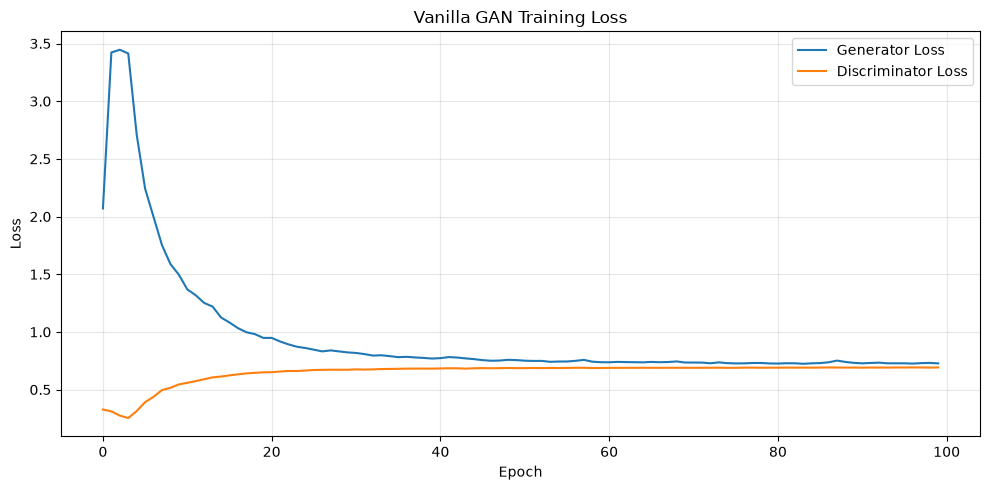

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(generator_losses, label="Generator Loss")
plt.plot(discriminator_losses, label="Discriminator Loss")

plt.title("Vanilla GAN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "vanilla_gan_training_curves.png",
    dpi=100,
    bbox_inches="tight"
)

plt.show()

Best Checkpoint

In [13]:
checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

generator.load_state_dict(checkpoint["generator_state_dict"])
discriminator.load_state_dict(checkpoint["discriminator_state_dict"])

generator.eval()
discriminator.eval()

print("Checkpoint Epoch:", checkpoint["epoch"])
print("Checkpoint Exists:", checkpoint_path.exists())

Checkpoint Epoch: 100
Checkpoint Exists: True


Generate Images

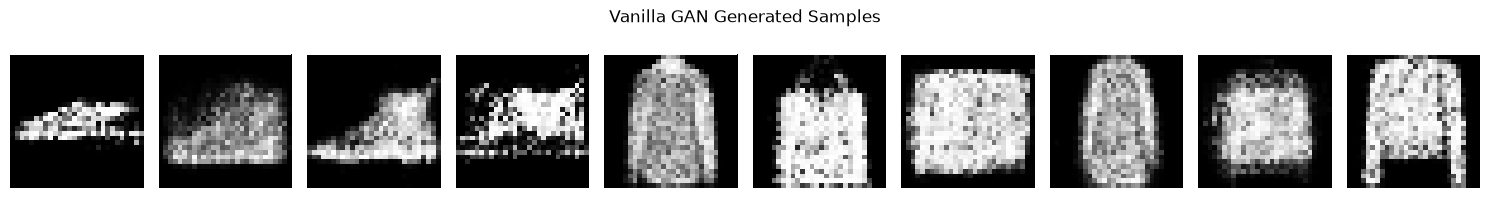

In [17]:
with torch.no_grad():
    generated_images = generator(fixed_noise).cpu()

fig, axes = plt.subplots(1, 10, figsize=(15, 2))

for i, ax in enumerate(axes):
    image = (generated_images[i].squeeze() + 1) / 2

    ax.imshow(image, cmap="gray")
    ax.axis("off")

plt.suptitle("Vanilla GAN Generated Samples")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "vanilla_gan_generated_samples.png",
    dpi=100,
    bbox_inches="tight"
)

plt.show()

In [19]:
generator.load_state_dict(checkpoint["generator_state_dict"])
discriminator.load_state_dict(checkpoint["discriminator_state_dict"])

generator_optimizer.load_state_dict(
    checkpoint["generator_optimizer_state_dict"]
)
discriminator_optimizer.load_state_dict(
    checkpoint["discriminator_optimizer_state_dict"]
)

generator_losses = checkpoint["generator_losses"]
discriminator_losses = checkpoint["discriminator_losses"]

START_EPOCH = checkpoint["epoch"]
EPOCHS = 150

print("Starting Epoch:", START_EPOCH + 1)
print("Target Epoch:", EPOCHS)
print("Previous Generator Loss:", generator_losses[-1])
print("Previous Discriminator Loss:", discriminator_losses[-1])

Starting Epoch: 101
Target Epoch: 150
Previous Generator Loss: 0.7272970368873038
Previous Discriminator Loss: 0.6920753079190102


In [20]:
for epoch in range(START_EPOCH, EPOCHS):
    generator.train()
    discriminator.train()

    total_g_loss = 0
    total_d_loss = 0

    for (real_images,) in train_loader:
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        # Train Discriminator
        discriminator_optimizer.zero_grad()

        real_output = discriminator(real_images)
        real_loss = criterion(real_output, real_labels)

        noise = torch.randn(batch_size, NOISE_DIM).to(device)
        fake_images = generator(noise)

        fake_output = discriminator(fake_images.detach())
        fake_loss = criterion(fake_output, fake_labels)

        d_loss = (real_loss + fake_loss) / 2
        d_loss.backward()
        discriminator_optimizer.step()

        # Train Generator
        generator_optimizer.zero_grad()

        for p in discriminator.parameters():
            p.requires_grad = False

        noise = torch.randn(batch_size, NOISE_DIM).to(device)
        generated_images = generator(noise)

        output = discriminator(generated_images)
        g_loss = criterion(output, real_labels)

        g_loss.backward()
        generator_optimizer.step()

        for p in discriminator.parameters():
            p.requires_grad = True

        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    avg_d_loss = total_d_loss / len(train_loader)
    avg_g_loss = total_g_loss / len(train_loader)

    generator_losses.append(avg_g_loss)
    discriminator_losses.append(avg_d_loss)

    # Save checkpoint every 10 epochs
    if (epoch + 1) % 10 == 0:
        torch.save({
            "epoch": epoch + 1,
            "generator_state_dict": generator.state_dict(),
            "discriminator_state_dict": discriminator.state_dict(),
            "generator_optimizer_state_dict": generator_optimizer.state_dict(),
            "discriminator_optimizer_state_dict": discriminator_optimizer.state_dict(),
            "generator_losses": generator_losses,
            "discriminator_losses": discriminator_losses
        }, checkpoint_path)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1}/{EPOCHS}] "
            f"Generator Loss: {avg_g_loss:.6f} "
            f"Discriminator Loss: {avg_d_loss:.6f}"
        )

Epoch [110/150] Generator Loss: 0.725374 Discriminator Loss: 0.690995
Epoch [120/150] Generator Loss: 0.730577 Discriminator Loss: 0.690353
Epoch [130/150] Generator Loss: 0.728295 Discriminator Loss: 0.691801
Epoch [140/150] Generator Loss: 0.723435 Discriminator Loss: 0.691761
Epoch [150/150] Generator Loss: 0.719836 Discriminator Loss: 0.690932


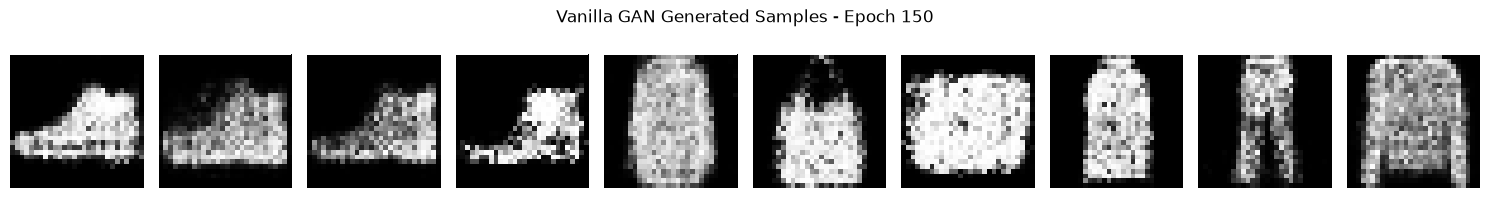

In [27]:
generator.eval()

with torch.no_grad():
    generated_images_150 = generator(fixed_noise).cpu()

fig, axes = plt.subplots(1, 10, figsize=(15, 2))

for i, ax in enumerate(axes):
    image = (generated_images_150[i].squeeze() + 1) / 2
    ax.imshow(image, cmap="gray")
    ax.axis("off")

plt.suptitle("Vanilla GAN Generated Samples - Epoch 150")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "vanilla_gan_generated_samples_150.png",
    dpi=100,
    bbox_inches="tight"
)

plt.show()

In [30]:
checkpoint_v1_path = CHECKPOINTS_DIR / "vanilla_gan_epoch150_v1.pth"

checkpoint_v1 = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)

torch.save(checkpoint_v1, checkpoint_v1_path)

print("Version 1 checkpoint backed up:", checkpoint_v1_path.exists())
print("Saved Epoch:", checkpoint_v1["epoch"])

Version 1 checkpoint backed up: True
Saved Epoch: 150


==============================

In [31]:
class GeneratorV2(nn.Module):
    def __init__(self, config):
        super(GeneratorV2, self).__init__()

        dimensions = config["generator"]
        layers = []

        for i in range(len(dimensions) - 1):
            layers.append(
                nn.Linear(dimensions[i], dimensions[i + 1])
            )

            if i < len(dimensions) - 2:
                layers.append(nn.BatchNorm1d(dimensions[i + 1]))
                layers.append(nn.ReLU())

            else:
                layers.append(nn.Tanh())

        self.model = nn.Sequential(*layers)

    def forward(self, z):
        generated = self.model(z)
        return generated.view(-1, 1, 28, 28)


generator_v2 = GeneratorV2(GAN_CONFIG).to(device)

print(generator_v2)

GeneratorV2(
  (model): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=512, bias=True)
    (4): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=512, out_features=1024, bias=True)
    (7): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU()
    (9): Linear(in_features=1024, out_features=784, bias=True)
    (10): Tanh()
  )
)


In [32]:
class DiscriminatorV2(nn.Module):
    def __init__(self, config):
        super(DiscriminatorV2, self).__init__()

        dimensions = config["discriminator"]
        layers = []

        for i in range(len(dimensions) - 1):
            layers.append(
                nn.Linear(dimensions[i], dimensions[i + 1])
            )

            if i < len(dimensions) - 2:
                layers.append(nn.LeakyReLU(0.2))
                layers.append(nn.Dropout(0.3))

            else:
                layers.append(nn.Sigmoid())

        self.model = nn.Sequential(*layers)

    def forward(self, images):
        images = images.view(images.size(0), -1)
        return self.model(images)


discriminator_v2 = DiscriminatorV2(GAN_CONFIG).to(device)

print(discriminator_v2)

DiscriminatorV2(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): LeakyReLU(negative_slope=0.2)
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=256, out_features=1, bias=True)
    (7): Sigmoid()
  )
)


In [33]:
criterion_v2 = nn.BCELoss()

generator_optimizer_v2 = optim.Adam(
    generator_v2.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

discriminator_optimizer_v2 = optim.Adam(
    discriminator_v2.parameters(),
    lr=0.0002,
    betas=(0.5, 0.999)
)

EPOCHS_V2 = 150
NOISE_DIM = GAN_CONFIG["noise_dim"]

generator_losses_v2 = []
discriminator_losses_v2 = []

fixed_noise_v2 = torch.randn(10, NOISE_DIM).to(device)

checkpoint_v2_path = CHECKPOINTS_DIR / "vanilla_gan_v2.pth"

print("Generator V2 and Discriminator V2 ready")
print("Epochs:", EPOCHS_V2)
print("Noise Dimension:", NOISE_DIM)
print("Checkpoint:", checkpoint_v2_path)

Generator V2 and Discriminator V2 ready
Epochs: 150
Noise Dimension: 100
Checkpoint: d:\generative-models-comparison\checkpoints\vanilla_gan_v2.pth


In [34]:
for epoch in range(EPOCHS_V2):
    generator_v2.train()
    discriminator_v2.train()

    total_g_loss = 0
    total_d_loss = 0

    for (real_images,) in train_loader:
        real_images = real_images.to(device)
        batch_size = real_images.size(0)

        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)

        # Train Discriminator
        discriminator_optimizer_v2.zero_grad()

        real_output = discriminator_v2(real_images)
        real_loss = criterion_v2(real_output, real_labels)

        noise = torch.randn(batch_size, NOISE_DIM).to(device)
        fake_images = generator_v2(noise)

        fake_output = discriminator_v2(fake_images.detach())
        fake_loss = criterion_v2(fake_output, fake_labels)

        d_loss = (real_loss + fake_loss) / 2
        d_loss.backward()
        discriminator_optimizer_v2.step()

        # Train Generator
        generator_optimizer_v2.zero_grad()

        for p in discriminator_v2.parameters():
            p.requires_grad = False

        noise = torch.randn(batch_size, NOISE_DIM).to(device)
        generated_images = generator_v2(noise)

        output = discriminator_v2(generated_images)
        g_loss = criterion_v2(output, real_labels)

        g_loss.backward()
        generator_optimizer_v2.step()

        for p in discriminator_v2.parameters():
            p.requires_grad = True

        total_d_loss += d_loss.item()
        total_g_loss += g_loss.item()

    avg_d_loss = total_d_loss / len(train_loader)
    avg_g_loss = total_g_loss / len(train_loader)

    generator_losses_v2.append(avg_g_loss)
    discriminator_losses_v2.append(avg_d_loss)

    if (epoch + 1) % 10 == 0:
        torch.save({
            "epoch": epoch + 1,
            "generator_state_dict": generator_v2.state_dict(),
            "discriminator_state_dict": discriminator_v2.state_dict(),
            "generator_optimizer_state_dict": generator_optimizer_v2.state_dict(),
            "discriminator_optimizer_state_dict": discriminator_optimizer_v2.state_dict(),
            "generator_losses": generator_losses_v2,
            "discriminator_losses": discriminator_losses_v2
        }, checkpoint_v2_path)

        print(
            f"Epoch [{epoch + 1}/{EPOCHS_V2}] "
            f"Generator Loss: {avg_g_loss:.6f} "
            f"Discriminator Loss: {avg_d_loss:.6f}"
        )

Epoch [10/150] Generator Loss: 0.902582 Discriminator Loss: 0.662522
Epoch [20/150] Generator Loss: 0.785826 Discriminator Loss: 0.681916
Epoch [30/150] Generator Loss: 0.760538 Discriminator Loss: 0.685038
Epoch [40/150] Generator Loss: 0.739907 Discriminator Loss: 0.688142
Epoch [50/150] Generator Loss: 0.726464 Discriminator Loss: 0.689374
Epoch [60/150] Generator Loss: 0.721045 Discriminator Loss: 0.690002
Epoch [70/150] Generator Loss: 0.716412 Discriminator Loss: 0.689842
Epoch [80/150] Generator Loss: 0.713848 Discriminator Loss: 0.690810
Epoch [90/150] Generator Loss: 0.712231 Discriminator Loss: 0.690639
Epoch [100/150] Generator Loss: 0.709336 Discriminator Loss: 0.691331
Epoch [110/150] Generator Loss: 0.710319 Discriminator Loss: 0.691695
Epoch [120/150] Generator Loss: 0.705766 Discriminator Loss: 0.691930
Epoch [130/150] Generator Loss: 0.704936 Discriminator Loss: 0.691994
Epoch [140/150] Generator Loss: 0.703940 Discriminator Loss: 0.692319
Epoch [150/150] Generator Los

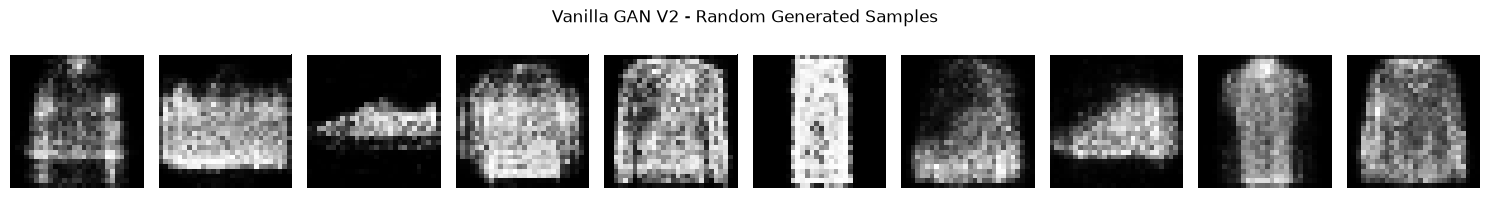

In [40]:
generator_v2.eval()

random_noise = torch.randn(10, NOISE_DIM).to(device)

with torch.no_grad():
    generated_images_v2 = generator_v2(random_noise).cpu()

fig, axes = plt.subplots(1, 10, figsize=(15, 2))

for i, ax in enumerate(axes):
    image = (generated_images_v2[i].squeeze() + 1) / 2
    ax.imshow(image, cmap="gray")
    ax.axis("off")

plt.suptitle("Vanilla GAN V2 - Random Generated Samples")
plt.tight_layout()
plt.show()

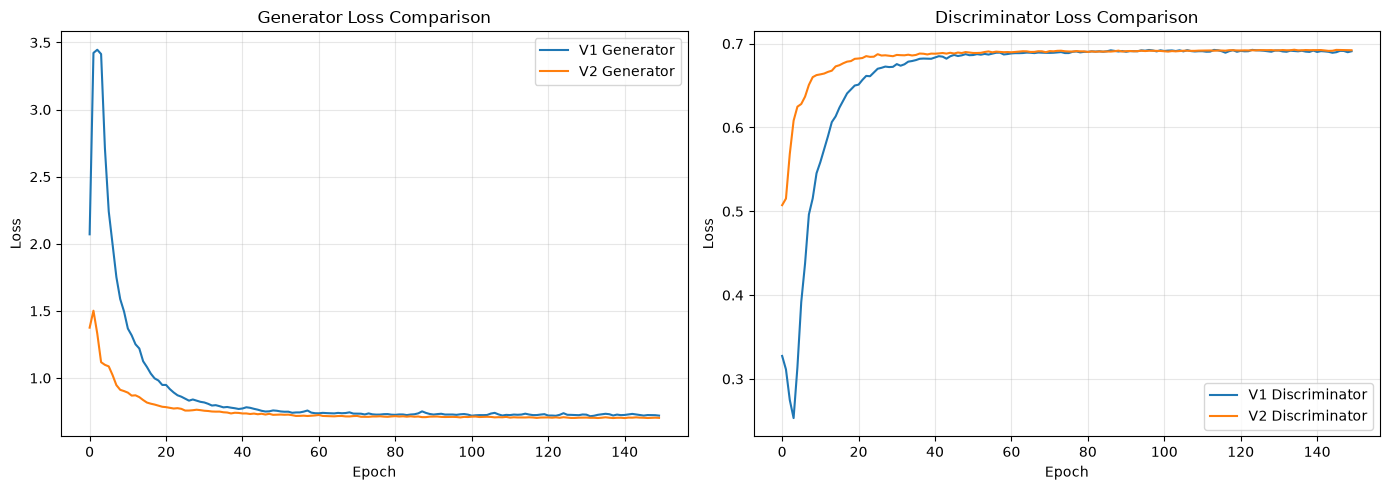

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Generator Loss
axes[0].plot(generator_losses, label="V1 Generator")
axes[0].plot(generator_losses_v2, label="V2 Generator")
axes[0].set_title("Generator Loss Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Discriminator Loss
axes[1].plot(discriminator_losses, label="V1 Discriminator")
axes[1].plot(discriminator_losses_v2, label="V2 Discriminator")
axes[1].set_title("Discriminator Loss Comparison")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "vanilla_gan_v1_v2_training_comparison.png",
    dpi=100,
    bbox_inches="tight"
)

plt.show()

In [42]:
vanilla_gan_files = [
    CHECKPOINTS_DIR / "vanilla_gan.pth",
    CHECKPOINTS_DIR / "vanilla_gan_epoch150_v1.pth",
    CHECKPOINTS_DIR / "vanilla_gan_v2.pth",
    RESULTS_DIR / "vanilla_gan_training_curves.png",
    RESULTS_DIR / "vanilla_gan_generated_samples.png",
    RESULTS_DIR / "vanilla_gan_generated_samples_150.png",
    RESULTS_DIR / "vanilla_gan_v2_generated_samples.png",
    RESULTS_DIR / "vanilla_gan_v1_v2_training_comparison.png"
]

for file_path in vanilla_gan_files:
    print(f"{file_path.name}: {'Exists' if file_path.exists() else 'Not Found'}")

vanilla_gan.pth: Exists
vanilla_gan_epoch150_v1.pth: Exists
vanilla_gan_v2.pth: Exists
vanilla_gan_training_curves.png: Exists
vanilla_gan_generated_samples.png: Exists
vanilla_gan_generated_samples_150.png: Exists
vanilla_gan_v2_generated_samples.png: Exists
vanilla_gan_v1_v2_training_comparison.png: Exists
